 HouseGuard: Deteksi Asap & Api (YOLO)

Notebook ini bisa dijalankan di **Kaggle** (untuk training pakai GPU) atau di **laptop lokal**.

- Model hasil training disimpan di folder `models`, folder yang sama dengan model deteksi kendaraan.
- Kalau model sudah pernah dilatih dan ada di folder `models`, training **dilewati otomatis**, jadi tidak perlu training ulang.
- Bagian akhir menampilkan hasil deteksi: grafik training, skor di data test, contoh gambar, dan tes di frame CCTV.

In [2]:
import os
import sys
import subprocess

DI_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

# Di Kaggle: install ultralytics versi yang SAMA dengan laptop (8.3.143),
# supaya model hasil training pasti bisa dibuka di lokal.
if DI_KAGGLE:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'ultralytics==8.3.143', 'kagglehub'], check=True)

import glob
import random
import shutil
import kagglehub
import cv2
import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO
from IPython.display import Image, display

ADA_GPU = torch.cuda.is_available()
print(f"Lingkungan  : {'Kaggle' if DI_KAGGLE else 'Lokal'}")
print(f"Ultralytics : {ultralytics.__version__}")
print(f"GPU         : {torch.cuda.get_device_name(0) if ADA_GPU else 'TIDAK ADA (CPU saja)'}")
if DI_KAGGLE and not ADA_GPU:
    print("\n⚠️ GPU belum aktif! Settings -> Accelerator -> GPU T4 x2, lalu jalankan ulang.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Lingkungan  : Kaggle
Ultralytics : 8.3.143
GPU         : Tesla T4


## 1. Pengaturan folder

In [3]:
if DI_KAGGLE:
    MODELS_DIR = '/kaggle/working/models'
else:
    # Folder model, sama dengan model deteksi kendaraan
    MODELS_DIR = r'C:\Users\NADIA\OneDrive\ドキュメント\airimpact\Deteksi_Kendaraan\Deteksi_Jumlah_Jenis_Kendaraan\models'

# Download dataset (hanya sekali, berikutnya pakai cache kagglehub).
# Di Kaggle ini cepat; di laptop sekitar 2,8 GB.
path = kagglehub.dataset_download("sayedgamal99/smoke-fire-detection-yolo")
print("Path to dataset files:", path)

# Cari folder root yang berisi data/train/images
DATASET_DIR = path
if not os.path.isdir(os.path.join(DATASET_DIR, 'data', 'train', 'images')):
    kandidat = glob.glob(os.path.join(path, '**', 'data', 'train', 'images'), recursive=True)
    if kandidat:
        DATASET_DIR = os.path.dirname(os.path.dirname(os.path.dirname(kandidat[0])))

RUNS_DIR    = os.path.join(os.getcwd(), 'runs')                    # log & grafik training
MODEL_FINAL = os.path.join(MODELS_DIR, 'houseguard_model_best.pt')  # model akhir yang dipakai
CONFIG_YAML = os.path.join(os.getcwd(), 'fire_config.yaml')
os.makedirs(MODELS_DIR, exist_ok=True)

# ---------- Ambil model otomatis dari Kaggle Models (khusus di laptop) ----------
KAGGLE_USERNAME = 'ISI_USERNAME_KAGGLE'        # <- ganti dengan username Kaggle lo
NAMA_MODEL_KAGGLE = 'houseguard-smoke-fire'
HANDLE_MODEL = f"{KAGGLE_USERNAME}/{NAMA_MODEL_KAGGLE}/pyTorch/yolov8n"

if not DI_KAGGLE and not os.path.exists(MODEL_FINAL) and KAGGLE_USERNAME != 'ISI_USERNAME_KAGGLE':
    try:
        print(f"Model belum ada di laptop, mengambil dari Kaggle Models: {HANDLE_MODEL}")
        folder_unduh = kagglehub.model_download(HANDLE_MODEL)
        ketemu = glob.glob(os.path.join(folder_unduh, '**', '*.pt'), recursive=True)
        if ketemu:
            shutil.copy(ketemu[0], MODEL_FINAL)
            print(f"✅ Model tersalin ke: {MODEL_FINAL}")
        else:
            print("Model di Kaggle Models tidak berisi file .pt.")
    except Exception as e:
        print(f"Gagal mengambil model dari Kaggle Models: {e}")

ADA_DATASET = os.path.isdir(os.path.join(DATASET_DIR, 'data', 'train', 'images'))
print(f"Lingkungan  : {'Kaggle' if DI_KAGGLE else 'Lokal'}")
print(f"Folder model: {MODELS_DIR}")
print(f"Dataset     : {DATASET_DIR} ({'ada' if ADA_DATASET else 'TIDAK DITEMUKAN'})")
print(f"Model akhir : {MODEL_FINAL} ({'sudah ada' if os.path.exists(MODEL_FINAL) else 'belum ada'})")

Path to dataset files: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo
Lingkungan  : Kaggle
Folder model: /kaggle/working/models
Dataset     : /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo (ada)
Model akhir : /kaggle/working/models/houseguard_model_best.pt (belum ada)


## 2. Konfigurasi dataset

In [4]:
config = {
    'path': DATASET_DIR,
    'train': 'data/train/images',
    'val': 'data/val/images',
    'test': 'data/test/images',
    'nc': 2,
    'names': ['smoke', 'fire'],
}
with open(CONFIG_YAML, 'w', encoding='utf-8') as f:
    yaml.safe_dump(config, f, allow_unicode=True, sort_keys=False)

print(f"✅ Konfigurasi dataset siap: {CONFIG_YAML}")
print(f"📂 Class names: {config['names']}")

✅ Konfigurasi dataset siap: /kaggle/working/fire_config.yaml
📂 Class names: ['smoke', 'fire']


## 3. Training (dilewati otomatis kalau model sudah ada)

Set `LATIH_ULANG = True` kalau memang mau training ulang dari awal.

In [5]:
LATIH_ULANG = False
IZINKAN_TRAINING_CPU = False   # training di CPU laptop sekitar 2,5 JAM PER EPOCH -> jalankan di Kaggle


def siapkan_model_dasar(nama, folder):
    """Download model dasar sekali ke folder models; run berikutnya pakai file lokal."""
    path = os.path.join(folder, nama)
    if os.path.isfile(path):
        print(f"Pakai model dasar lokal: {path}")
        return YOLO(path)
    print(f"Download model dasar {nama} sekali ke: {folder}")
    cwd = os.getcwd()
    try:
        os.chdir(folder)
        model = YOLO(nama)
    finally:
        os.chdir(cwd)
    return model


TRAIN_DIR = os.path.join(RUNS_DIR, 'houseguard_model')

if os.path.exists(MODEL_FINAL) and not LATIH_ULANG:
    print(f"⏭️ Model sudah ada, training dilewati: {MODEL_FINAL}")
elif not ADA_DATASET:
    print("❌ Dataset tidak ditemukan, training tidak bisa jalan. Cek DATASET_DIR di sel pengaturan.")
elif not ADA_GPU and not IZINKAN_TRAINING_CPU:
    print("⛔ Tidak ada GPU, training dibatalkan (di CPU bisa makan waktu berhari-hari).")
    print("   Jalankan notebook ini di Kaggle dengan GPU, lalu download model hasilnya.")
else:
    model = siapkan_model_dasar('yolov8n.pt', MODELS_DIR)
    print("🚀 Mulai Training HouseGuard ...")
    model.train(
        data=CONFIG_YAML,
        epochs=50,
        imgsz=640,
        batch=32,          # muat di GPU T4 (15 GB) untuk model nano
        device=0 if ADA_GPU else 'cpu',   # 1 GPU sudah cukup; multi-GPU dari notebook sering bermasalah
        project=RUNS_DIR,
        name='houseguard_model',
        exist_ok=True,
        patience=5,
    )
    TRAIN_DIR = str(model.trainer.save_dir)
    shutil.copy(os.path.join(TRAIN_DIR, 'weights', 'best.pt'), MODEL_FINAL)
    print(f"🏁 Training selesai! Model tersimpan di: {MODEL_FINAL}")

# ---------- Kirim model keluar dari Kaggle supaya tidak hilang ----------
def upload_ke_kaggle_models():
    """Upload model ke Kaggle Models (permanen). Butuh Secrets KAGGLE_USERNAME & KAGGLE_KEY."""
    try:
        from kaggle_secrets import UserSecretsClient
        rahasia = UserSecretsClient()
        os.environ['KAGGLE_USERNAME'] = rahasia.get_secret('KAGGLE_USERNAME')
        os.environ['KAGGLE_KEY'] = rahasia.get_secret('KAGGLE_KEY')
    except Exception as e:
        print(f"⚠️ Secrets KAGGLE_USERNAME / KAGGLE_KEY belum diatur, upload dilewati ({e}).")
        return
    folder_upload = '/kaggle/working/upload_model'
    os.makedirs(folder_upload, exist_ok=True)
    shutil.copy(MODEL_FINAL, folder_upload)
    handle = f"{os.environ['KAGGLE_USERNAME']}/houseguard-smoke-fire/pyTorch/yolov8n"
    try:
        kagglehub.model_upload(handle, folder_upload, license_name='Apache 2.0',
                               version_notes='YOLOv8n smoke & fire, 50 epoch')
        print(f"☁️ Model ter-upload ke Kaggle Models: {handle}")
        print("   Di laptop, notebook ini akan mengambilnya otomatis (isi KAGGLE_USERNAME di sel pengaturan).")
    except Exception as e:
        print(f"⚠️ Upload ke Kaggle Models gagal: {e}")


if DI_KAGGLE and os.path.exists(MODEL_FINAL):
    # 1) Link download langsung (berfungsi di sesi interaktif editor)
    from IPython.display import FileLink
    print("\n📥 Klik link ini untuk download model ke laptop:")
    display(FileLink(os.path.relpath(MODEL_FINAL, os.getcwd())))
    # 2) Simpan permanen di Kaggle Models, supaya bisa diambil otomatis dari laptop
    upload_ke_kaggle_models()

Download model dasar yolov8n.pt sekali ke: /kaggle/working/models


100%|██████████| 6.25M/6.25M [00:00<00:00, 193MB/s]


🚀 Mulai Training HouseGuard ...
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.143 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fire_config.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=houseguard_model, 

100%|██████████| 755k/755k [00:00<00:00, 40.7MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 158MB/s]


... (136 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 49/49 [00:15<00:00,  3.27it/s]


                   all       3094       3917      0.762      0.694      0.764      0.448
                 smoke       1545       1751      0.812      0.762      0.827      0.517
                  fire        875       2166      0.712      0.625      0.702      0.378
Speed: 0.1ms preprocess, 1.4ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/houseguard_model
🏁 Training selesai! Model tersimpan di: /kaggle/working/models/houseguard_model_best.pt

📥 Klik link ini untuk download model ke laptop:


/kaggle/working/models/houseguard_model_best.pt

⚠️ Secrets KAGGLE_USERNAME / KAGGLE_KEY belum diatur, upload dilewati (Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 146675539 and label KAGGLE_USERNAME.'], 'error': {'code': 5}, 'wasSuccessful': False}.).


---
# 4. Hasil Deteksi

### 4a. Grafik training
Hanya muncul kalau folder hasil training ada di komputer ini (misalnya baru selesai training di sini).

📊 Kurva loss & mAP selama training


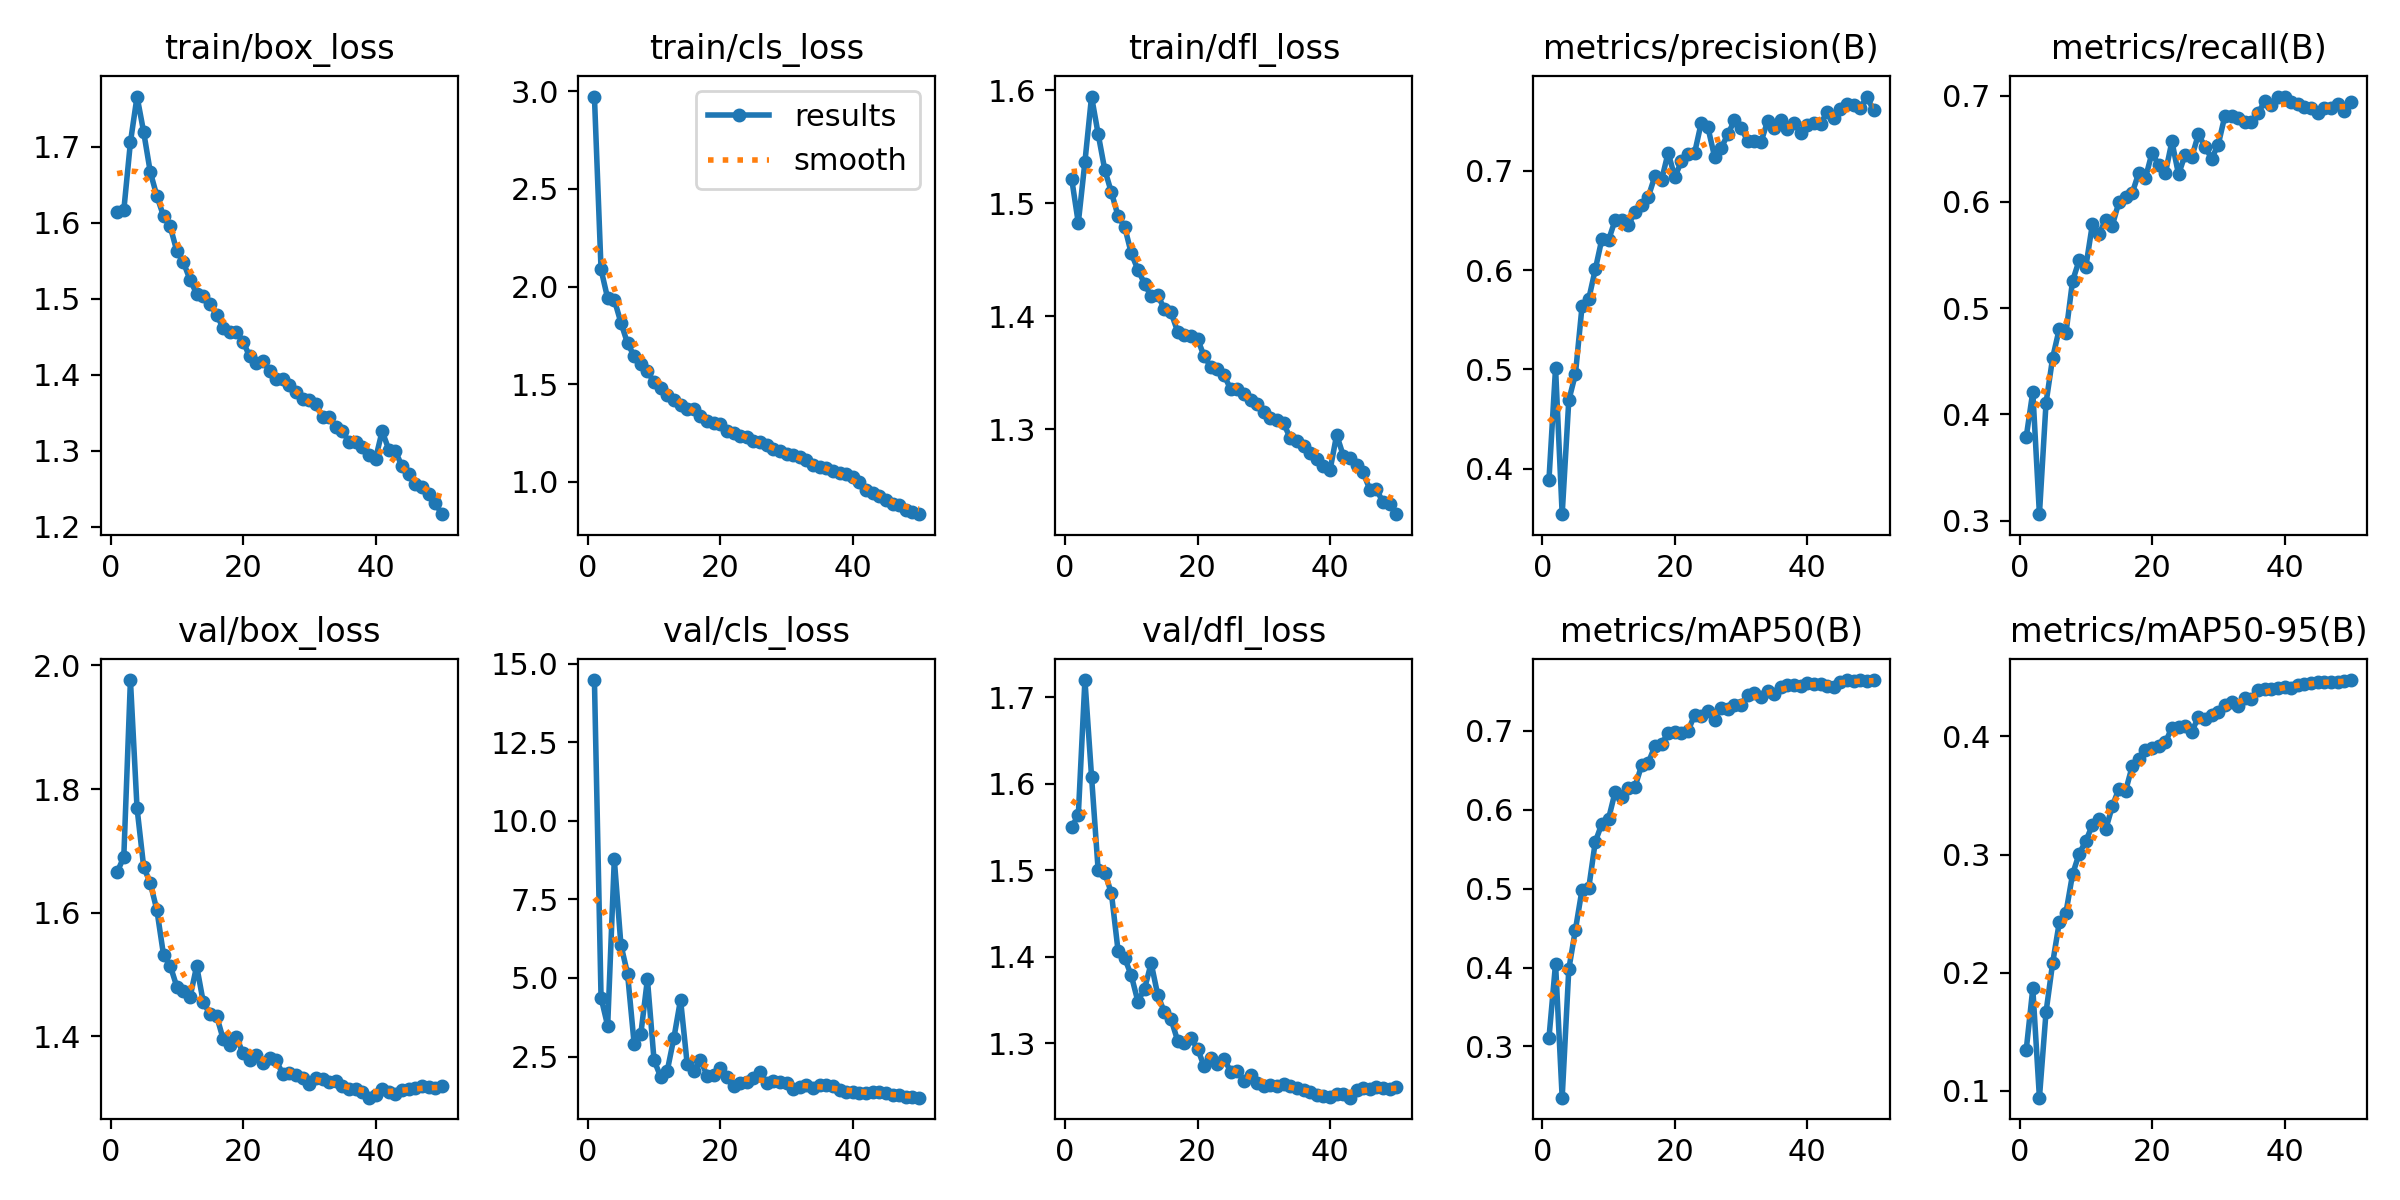

📊 Confusion matrix (dinormalisasi)


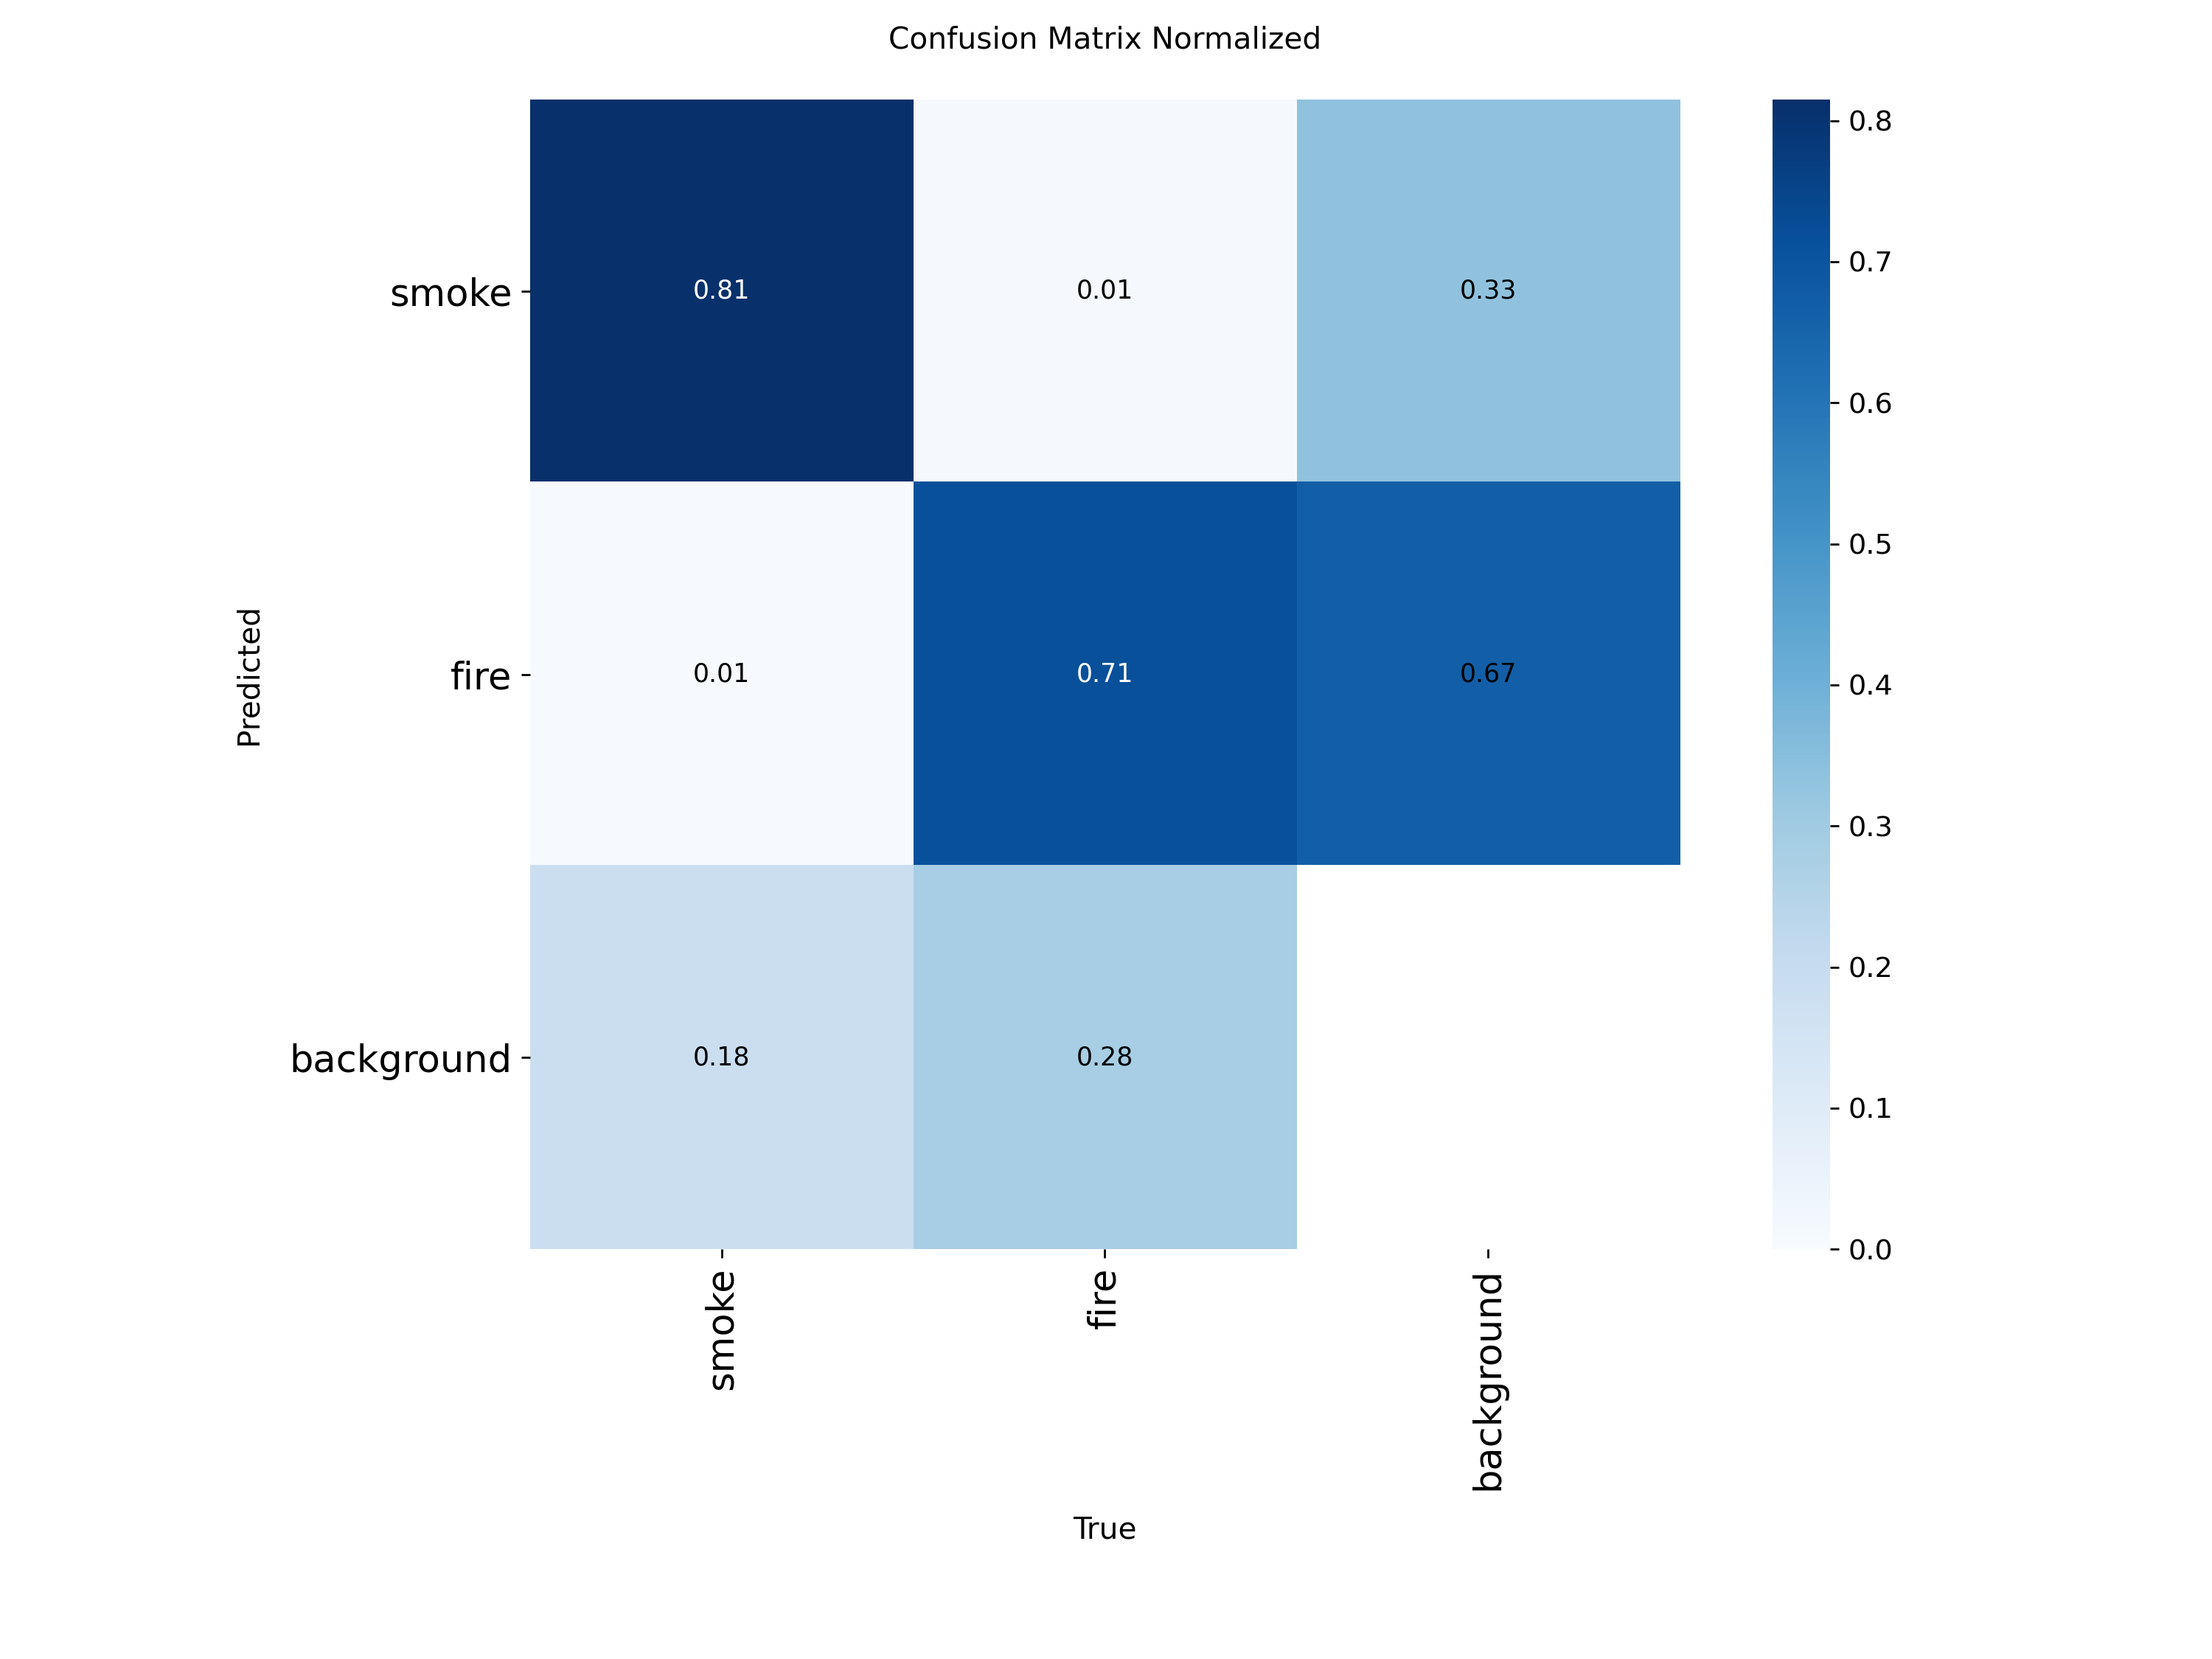

📊 Contoh prediksi di data validasi


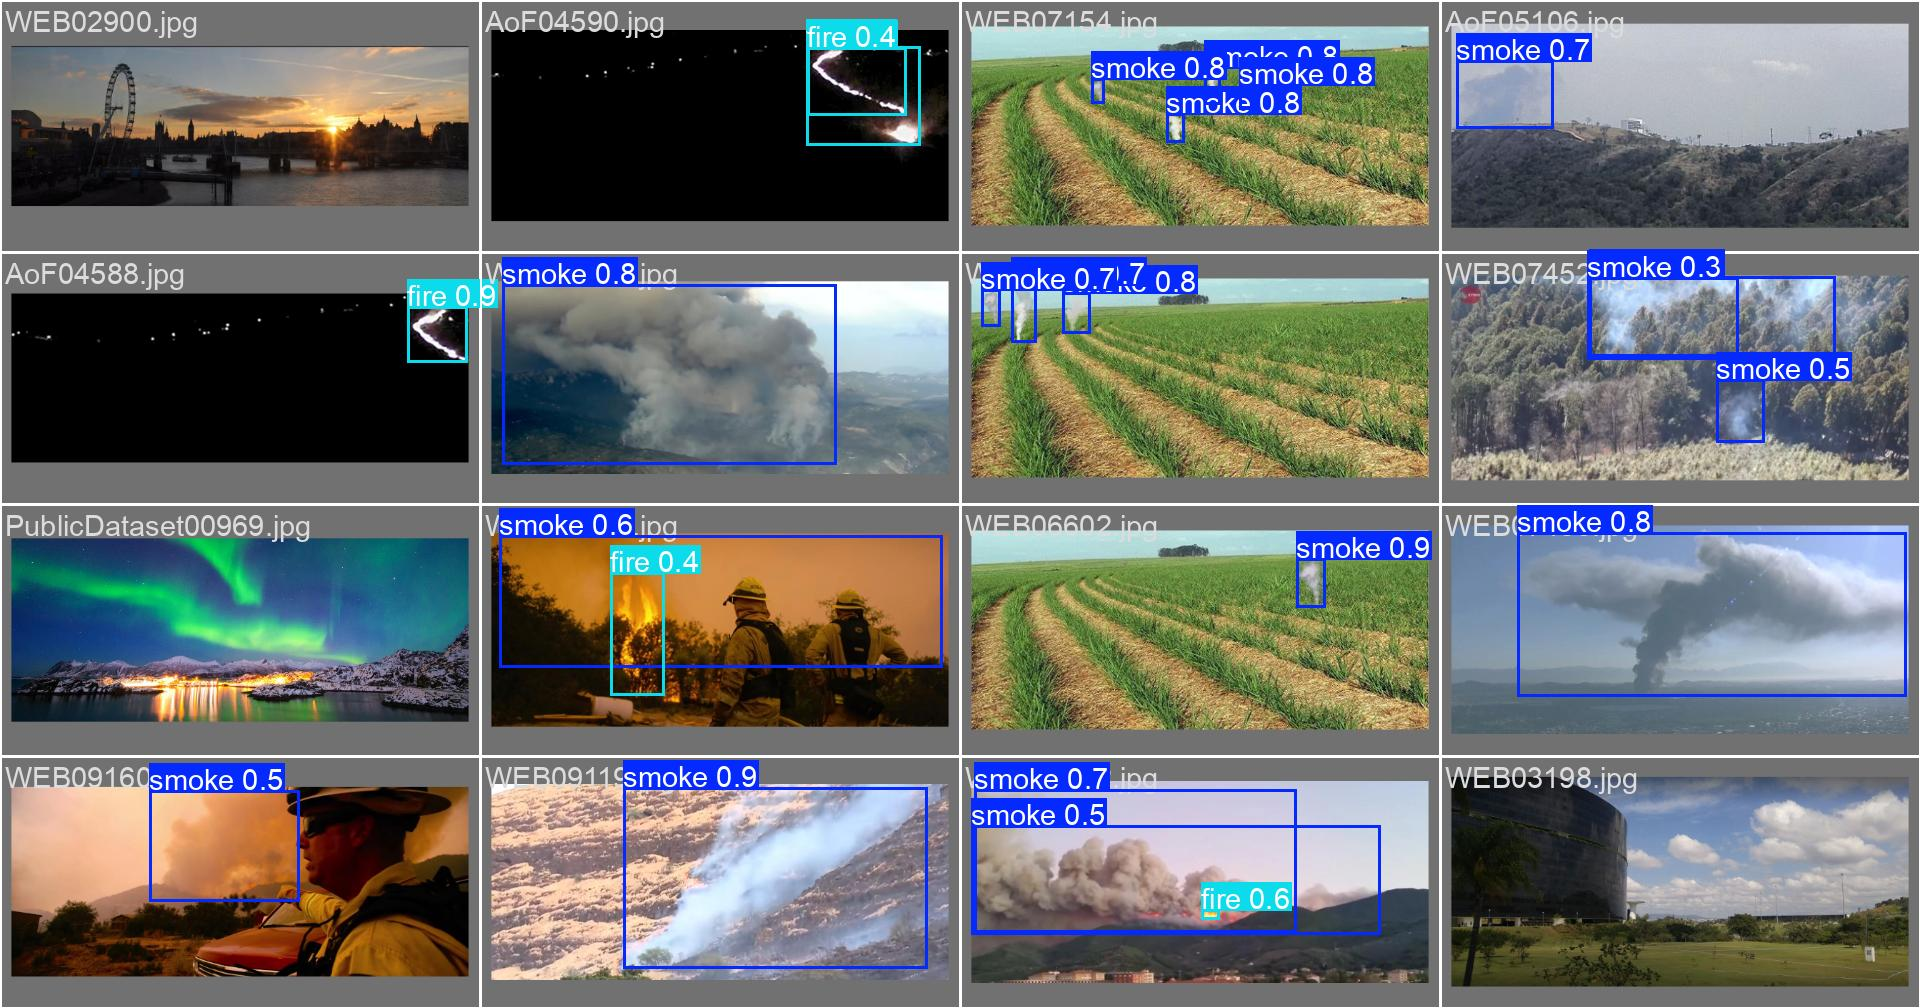

In [6]:
grafik = [
    ('Kurva loss & mAP selama training', 'results.png'),
    ('Confusion matrix (dinormalisasi)', 'confusion_matrix_normalized.png'),
    ('Contoh prediksi di data validasi', 'val_batch0_pred.jpg'),
]
ada_grafik = False
for judul, nama in grafik:
    path = os.path.join(TRAIN_DIR, nama)
    if os.path.exists(path):
        ada_grafik = True
        print(f"📊 {judul}")
        display(Image(filename=path, width=900))
if not ada_grafik:
    print(f"Folder hasil training tidak ditemukan di {TRAIN_DIR}, bagian ini dilewati.")

### 4b. Skor model di data test

In [ ]:
if os.path.exists(MODEL_FINAL):
    model_asap = YOLO(MODEL_FINAL)
    NAMA_KELAS = model_asap.names
    print(f"Kelas model: {NAMA_KELAS}")
else:
    model_asap = None
    print(f"Model belum ada di {MODEL_FINAL}. Bagian 4b-4d dilewati.")

if model_asap is not None and ADA_DATASET:
    metrics = model_asap.val(data=CONFIG_YAML, split='test', imgsz=640,
                             project=RUNS_DIR, name='test_eval', exist_ok=True, verbose=False)
    skor = pd.DataFrame({
        'Kelas': [NAMA_KELAS[i] for i in range(len(NAMA_KELAS))],
        'Precision': metrics.box.p,
        'Recall': metrics.box.r,
        'mAP50': metrics.box.ap50,
        'mAP50-95': metrics.box.ap,
    }).round(3)
    print("=== SKOR DI DATA TEST ===")
    print(skor.to_string(index=False))
    print(f"\nmAP50 rata-rata   : {metrics.box.map50:.3f}")
    print(f"mAP50-95 rata-rata: {metrics.box.map:.3f}")
elif model_asap is not None:
    print("Dataset tidak ada di komputer ini, evaluasi test dilewati.")

Kelas model: {0: 'smoke', 1: 'fire'}
Ultralytics 8.3.143 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.2 ms, read: 9.4±5.6 MB/s, size: 51.5 KB)


val: Scanning /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/labels... 4295 images, 2005 backgrounds, 19 corrupt: 100%|██████████| 4306/4306 [00:17<00:00, 245.19it/s]

val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/images/WEB10770.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0078125]
val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/images/WEB10821.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.009375]
val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/images/WEB11090.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0027778]
val: /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test/image

WARNING ⚠️ val: Cache directory /kaggle/input/datasets/sayedgamal99/smoke-fire-detection-yolo/data/test is not writeable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 268/268 [00:23<00:00, 11.41it/s]


                   all       4287       5156      0.758      0.693       0.76      0.438
Speed: 0.2ms preprocess, 2.4ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/runs/test_eval
=== SKOR DI DATA TEST ===
Kelas  Precision  Recall  mAP50  mAP50-95
smoke      0.796   0.766   0.82     0.505
 fire      0.720   0.620   0.70     0.372

mAP50 rata-rata   : 0.760
mAP50-95 rata-rata: 0.438


### 4c. Contoh hasil deteksi di gambar test

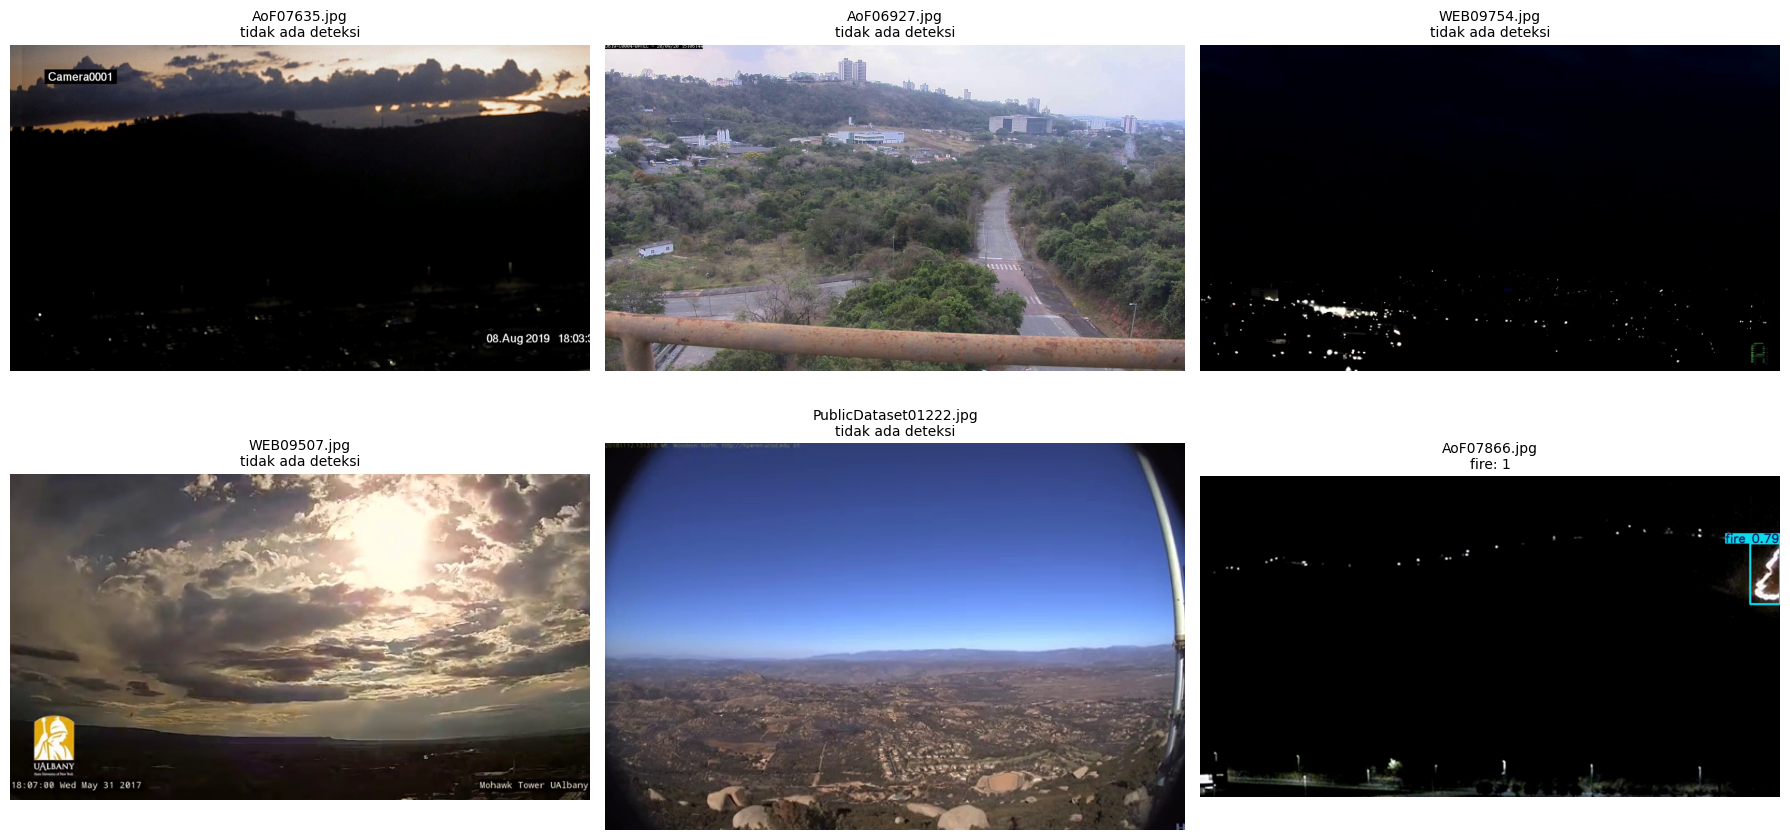

In [ ]:
JUMLAH_CONTOH = 6
CONF = 0.25

gambar_test = sorted(glob.glob(os.path.join(DATASET_DIR, 'data', 'test', 'images', '*')))
if model_asap is None:
    print("Model belum ada, bagian ini dilewati.")
elif not gambar_test:
    print("Gambar test tidak ditemukan, bagian ini dilewati.")
else:
    random.seed(42)
    contoh = random.sample(gambar_test, min(JUMLAH_CONTOH, len(gambar_test)))
    hasil = model_asap.predict(contoh, conf=CONF, imgsz=640, verbose=False)

    kolom = 3
    baris = (len(contoh) + kolom - 1) // kolom
    fig, axes = plt.subplots(baris, kolom, figsize=(6 * kolom, 4.5 * baris))
    axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

    for ax, r, path in zip(axes, hasil, contoh):
        ax.imshow(r.plot()[:, :, ::-1])   # BGR -> RGB
        jenis = [NAMA_KELAS[int(c)] for c in r.boxes.cls]
        ringkas = ', '.join(f"{k}: {jenis.count(k)}" for k in sorted(set(jenis))) or 'tidak ada deteksi'
        ax.set_title(f"{os.path.basename(path)}\n{ringkas}", fontsize=10)
        ax.axis('off')
    for ax in axes[len(contoh):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

✅ Data uji siap: 1000 gambar x 6 kondisi
Ultralytics 8.3.143 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2731.6±578.9 MB/s, size: 213.0 KB)


val: Scanning /kaggle/working/robustness/bersih/labels... 1000 images, 488 backgrounds, 4 corrupt: 100%|██████████| 1000/1000 [00:00<00:00, 1544.37it/s]

val: /kaggle/working/robustness/bersih/images/WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: /kaggle/working/robustness/bersih/images/WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: /kaggle/working/robustness/bersih/images/WEB11090.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0027778]
val: /kaggle/working/robustness/bersih/images/WEB11600.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.05625]
val: New cache created: /kaggle/working/robustness/bersih/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 63/63 [00:04<00:00, 13.27it/s]

                   all        996       1140      0.772      0.687      0.754      0.433
Speed: 0.1ms preprocess, 2.5ms inference, 0.0ms loss, 0.8ms postprocess per image
bersih                   mAP50 = 0.754
Ultralytics 8.3.143 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 930.4±415.3 MB/s, size: 31.4 KB)



val: Scanning /kaggle/working/robustness/blur/labels... 1000 images, 488 backgrounds, 4 corrupt: 100%|██████████| 1000/1000 [00:00<00:00, 1563.30it/s]

... (21 outputs left out)

                   all        996       1140      0.468      0.373       0.35      0.165
Speed: 0.1ms preprocess, 2.4ms inference, 0.0ms loss, 1.0ms postprocess per image


gelap_noise_dicerahkan   mAP50 = 0.350

=== HASIL UJI ROBUSTNESS ===


,Precision,Recall,mAP50,mAP50-95,mAP50 smoke,mAP50 fire,Perubahan mAP50 (%)
Kondisi,,,,,,,
bersih,0.772,0.687,0.754,0.433,0.830,0.679,0.000
blur,0.741,0.667,0.728,0.415,0.809,0.648,-3.463
motion_blur,0.663,0.549,0.601,0.321,0.655,0.548,-20.282
gelap,0.701,0.606,0.666,0.354,0.698,0.633,-11.730
gelap_noise,0.663,0.486,0.549,0.277,0.501,0.598,-27.201
gelap_noise_dicerahkan,0.468,0.373,0.350,0.165,0.274,0.426,-53.567


mAP50 bersih              : 0.754
mAP50 rata-rata kond. sulit: 0.636  (84.3% dari kondisi bersih)
Skor akhir (0,4 bersih + 0,6 sulit): 0.683
Efek mode malam           : -0.199 mAP50 (tidak membantu)


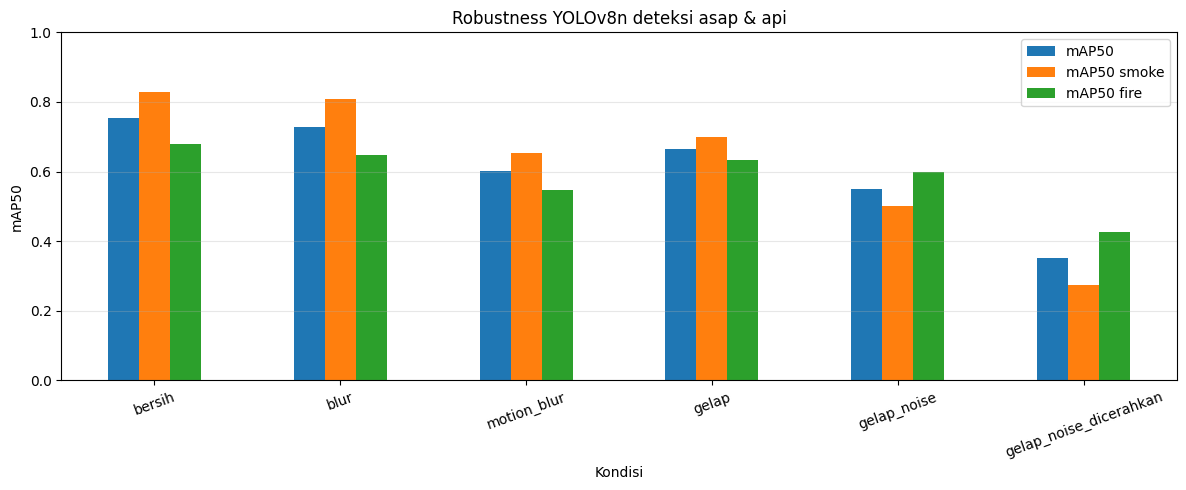

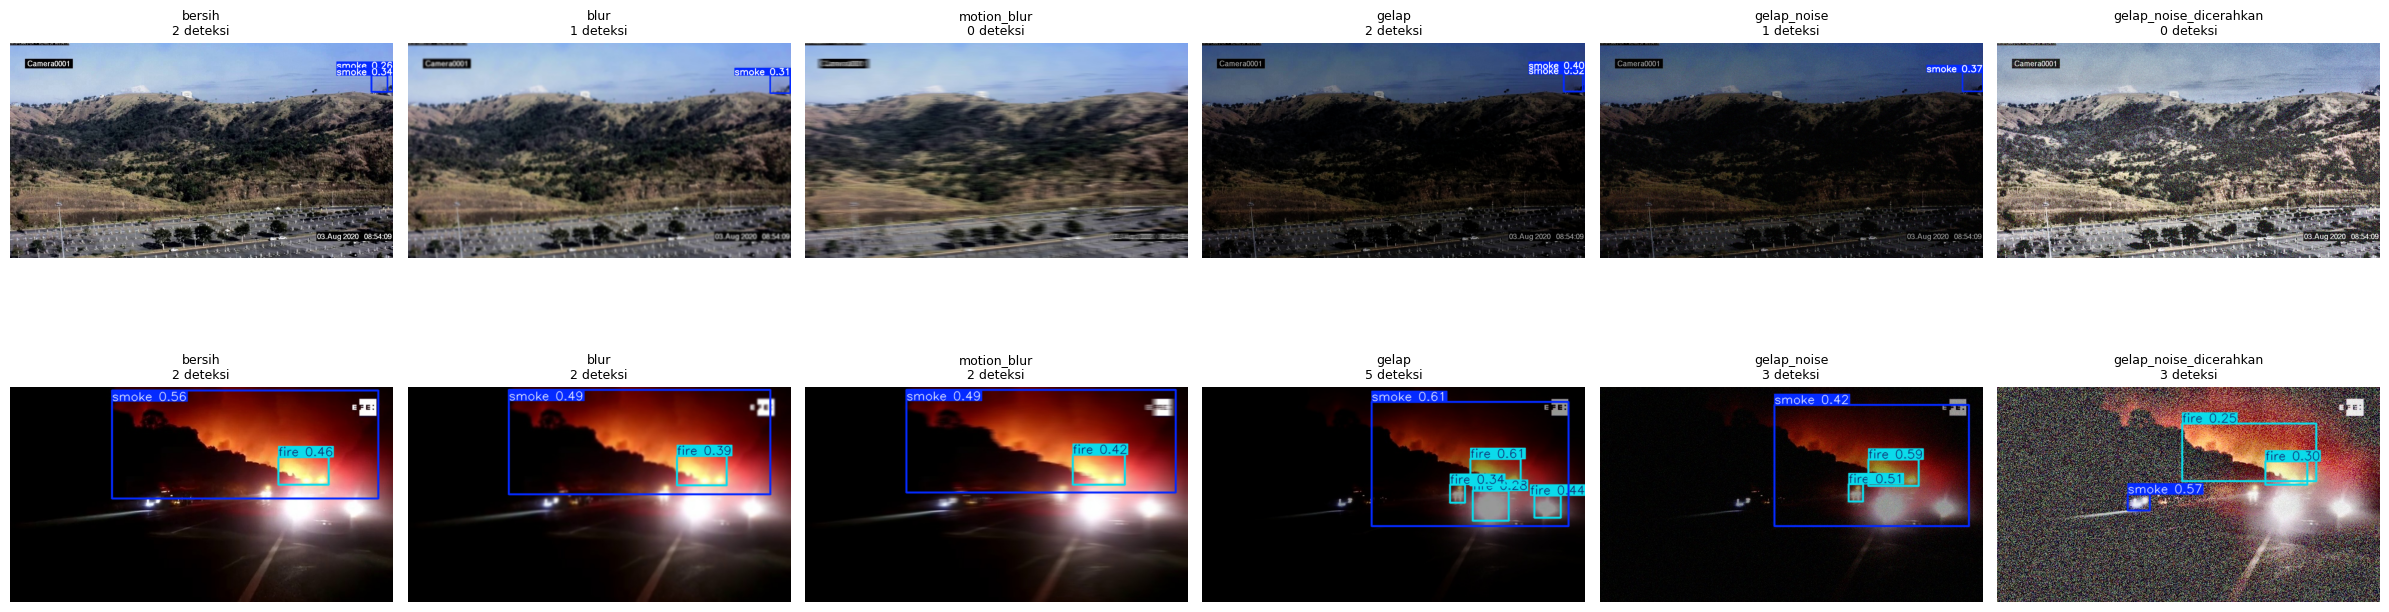

In [11]:
# ===================== UJI ROBUSTNESS: BLUR & CAHAYA RENDAH =====================
import numpy as np

N_ROBUST   = 1000 if DI_KAGGLE else 200          # di laptop (CPU) pakai sampel lebih kecil
ROBUST_DIR = os.path.join(os.getcwd(), 'robustness')
HASIL_DIR  = os.path.join(os.getcwd(), 'hasil_robustness')
os.makedirs(HASIL_DIR, exist_ok=True)
_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def _ganjil(x):
    x = max(3, int(round(x)))
    return x if x % 2 else x + 1

def blur(im, rng):                                 # kamera tidak fokus / lensa berembun
    k = _ganjil(min(im.shape[:2]) / 60)
    return cv2.GaussianBlur(im, (k, k), 0)

def motion_blur(im, rng):                          # objek bergerak cepat / kamera bergetar
    k = _ganjil(min(im.shape[:2]) / 30)
    kernel = np.zeros((k, k), np.float32)
    kernel[k // 2, :] = 1.0 / k
    return cv2.filter2D(im, -1, kernel)

def gelap(im, rng):                                # malam / cahaya kurang
    x = im.astype(np.float32) / 255.0
    return np.clip((x ** 2.0) * 0.6 * 255, 0, 255).astype(np.uint8)

def gelap_noise(im, rng):                          # malam + noise sensor CCTV
    x = gelap(im, rng).astype(np.float32) + rng.normal(0, 8, im.shape)
    return np.clip(x, 0, 255).astype(np.uint8)

def mode_malam(im):                                # sama dengan mode malam di deteksi_kendaraan.py
    kecil = cv2.resize(im, (160, max(1, int(160 * im.shape[0] / im.shape[1]))))
    terang = max(float(np.median(cv2.cvtColor(kecil, cv2.COLOR_BGR2GRAY))) / 255.0, 0.02)
    gamma = min(max(np.log(0.45) / np.log(terang), 0.35), 1.0)
    tabel = np.clip(((np.arange(256) / 255.0) ** gamma) * 255, 0, 255).astype(np.uint8)
    l, a, b = cv2.split(cv2.cvtColor(cv2.LUT(im, tabel), cv2.COLOR_BGR2LAB))
    return cv2.cvtColor(cv2.merge((_clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)

KONDISI = {
    'bersih':                 lambda im, rng: im,
    'blur':                   blur,
    'motion_blur':            motion_blur,
    'gelap':                  gelap,
    'gelap_noise':            gelap_noise,
    'gelap_noise_dicerahkan': lambda im, rng: mode_malam(gelap_noise(im, rng)),
}
KONDISI_SULIT = ['blur', 'motion_blur', 'gelap', 'gelap_noise']

def path_label(path_gambar):
    folder, nama = os.path.split(path_gambar)
    return os.path.join(os.path.dirname(folder), 'labels', os.path.splitext(nama)[0] + '.txt')

gambar_uji = [g for g in gambar_test if g.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]

if model_asap is None:
    print("Model belum ada, bagian ini dilewati.")
elif not gambar_uji:
    print("Gambar test tidak ditemukan, bagian ini dilewati.")
else:
    nama_kelas = [model_asap.names[i] for i in range(len(model_asap.names))]
    random.seed(42)
    sampel = random.sample(gambar_uji, min(N_ROBUST, len(gambar_uji)))

    # ---------- 1. Buat data uji per kondisi ----------
    yaml_kondisi = {}
    for kond, fungsi in KONDISI.items():
        f_img = os.path.join(ROBUST_DIR, kond, 'images')
        f_lbl = os.path.join(ROBUST_DIR, kond, 'labels')
        os.makedirs(f_img, exist_ok=True)
        os.makedirs(f_lbl, exist_ok=True)
        if len(os.listdir(f_img)) < len(sampel):           # buat hanya kalau belum lengkap
            for i, g in enumerate(sampel):
                im = cv2.imread(g)
                if im is None:
                    continue
                cv2.imwrite(os.path.join(f_img, os.path.basename(g)), fungsi(im, np.random.default_rng(i)))
                if os.path.exists(path_label(g)):
                    shutil.copy(path_label(g), f_lbl)
        y = os.path.join(ROBUST_DIR, f'{kond}.yaml')
        with open(y, 'w', encoding='utf-8') as f:
            yaml.safe_dump({'path': os.path.join(ROBUST_DIR, kond), 'train': 'images', 'val': 'images',
                            'nc': len(nama_kelas), 'names': nama_kelas}, f, allow_unicode=True)
        yaml_kondisi[kond] = y
    print(f"✅ Data uji siap: {len(sampel)} gambar x {len(KONDISI)} kondisi")

    # ---------- 2. Evaluasi model di setiap kondisi ----------
    baris = []
    for kond, y in yaml_kondisi.items():
        r = model_asap.val(data=y, split='val', imgsz=640, batch=16,
                           device=0 if ADA_GPU else 'cpu', plots=False, verbose=False,
                           project=RUNS_DIR, name='robust_eval', exist_ok=True)
        h = {'Kondisi': kond, 'Precision': float(r.box.mp), 'Recall': float(r.box.mr),
             'mAP50': float(r.box.map50), 'mAP50-95': float(r.box.map)}
        for j, c in enumerate(r.box.ap_class_index):
            h[f'mAP50 {nama_kelas[int(c)]}'] = float(r.box.ap50[j])
        baris.append(h)
        print(f"{kond:24s} mAP50 = {h['mAP50']:.3f}")

    df_robust = pd.DataFrame(baris).set_index('Kondisi')
    dasar = df_robust.loc['bersih', 'mAP50']
    df_robust['Perubahan mAP50 (%)'] = (df_robust['mAP50'] / dasar - 1) * 100
    df_robust.to_csv(os.path.join(HASIL_DIR, 'robustness_yolov8n.csv'))

    print("\n=== HASIL UJI ROBUSTNESS ===")
    display(df_robust.round(3))

    rata_sulit = df_robust.loc[KONDISI_SULIT, 'mAP50'].mean()
    print(f"mAP50 bersih              : {dasar:.3f}")
    print(f"mAP50 rata-rata kond. sulit: {rata_sulit:.3f}  ({rata_sulit / dasar * 100:.1f}% dari kondisi bersih)")
    print(f"Skor akhir (0,4 bersih + 0,6 sulit): {0.4 * dasar + 0.6 * rata_sulit:.3f}")
    if {'gelap_noise', 'gelap_noise_dicerahkan'} <= set(df_robust.index):
        efek = df_robust.loc['gelap_noise_dicerahkan', 'mAP50'] - df_robust.loc['gelap_noise', 'mAP50']
        print(f"Efek mode malam           : {efek:+.3f} mAP50 ({'membantu' if efek > 0 else 'tidak membantu'})")

    # ---------- 3. Grafik ----------
    kolom_grafik = ['mAP50'] + [c for c in df_robust.columns if c.startswith('mAP50 ')]
    ax = df_robust[kolom_grafik].plot(kind='bar', figsize=(12, 5), rot=20)
    ax.set_ylim(0, 1); ax.set_ylabel('mAP50'); ax.grid(axis='y', alpha=0.3)
    ax.set_title('Robustness YOLOv8n deteksi asap & api')
    plt.tight_layout()
    plt.savefig(os.path.join(HASIL_DIR, 'grafik_robustness_yolov8n.png'), dpi=150)
    plt.show()

    # ---------- 4. Contoh deteksi di setiap kondisi ----------
    random.seed(7)
    contoh_r = random.sample(sampel, min(2, len(sampel)))
    fig, axes = plt.subplots(len(contoh_r), len(KONDISI), figsize=(4 * len(KONDISI), 4 * len(contoh_r)))
    axes = np.atleast_2d(axes)
    for b, g in enumerate(contoh_r):
        for k, kond in enumerate(KONDISI):
            p = os.path.join(ROBUST_DIR, kond, 'images', os.path.basename(g))
            r = model_asap.predict(p, conf=CONF, imgsz=640, verbose=False)[0]
            axes[b, k].imshow(r.plot()[:, :, ::-1])
            axes[b, k].set_title(f"{kond}\n{len(r.boxes)} deteksi", fontsize=9)
            axes[b, k].axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(HASIL_DIR, 'contoh_deteksi_kondisi.png'), dpi=120)
    plt.show()

### 4d. Tes di frame CCTV asli
Ambil satu frame dari stream CCTV (atau file video) lalu jalankan deteksi asap/api.
Kalau tidak ada kebakaran, hasil yang **benar** adalah *tidak ada deteksi*. Kalau ada kotak muncul, itu deteksi palsu yang perlu diperhatikan.

In [ ]:
# Kamera Jl. Manggarai Utara 2 (Jakarta). Di Kaggle bisa saja gagal karena akses jaringan; itu wajar.
SUMBER_VIDEO = "https://dki-jkt.balitower.co.id:7028/501594_JKS_DISGULKARMAT_JL.-MANGGARAI-UTARA-2-C01_CCTV-01/index.fmp4.m3u8"
CONF_CCTV = 0.25

ok, frame = False, None
if model_asap is None:
    print("Model belum ada, bagian ini dilewati.")
else:
    try:  # batasi waktu tunggu supaya notebook tidak macet kalau stream tidak bisa diakses
        cap = cv2.VideoCapture(SUMBER_VIDEO, cv2.CAP_FFMPEG,
                               [cv2.CAP_PROP_OPEN_TIMEOUT_MSEC, 15000, cv2.CAP_PROP_READ_TIMEOUT_MSEC, 15000])
    except Exception:
        cap = cv2.VideoCapture(SUMBER_VIDEO, cv2.CAP_FFMPEG)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        print("Gagal membaca frame dari sumber video. Cek URL / koneksi (di Kaggle ini wajar, tes di laptop).")

if ok:
    r = model_asap.predict(frame, conf=CONF_CCTV, imgsz=640, verbose=False)[0]
    plt.figure(figsize=(14, 8))
    plt.imshow(r.plot()[:, :, ::-1])
    plt.axis('off')
    plt.title('Deteksi asap/api di frame CCTV')
    plt.show()

    if len(r.boxes) == 0:
        print("Tidak ada asap/api terdeteksi di frame ini.")
    else:
        print("Deteksi:")
        for c, s in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            print(f"  - {NAMA_KELAS[int(c)]}: confidence {s:.2f}")

Gagal membaca frame dari sumber video. Cek URL / koneksi (di Kaggle ini wajar, tes di laptop).


[hls @ 0x72cf12c0] detected format mov,mp4,m4a,3gp,3g2,mj2 extension mov,mp4,m4a,3gp,3g2,mj2,psp,m4b,ism,ismv,isma,f4v,avif,heic,heif mismatches allowed extensions in url https://dki-jkt.balitower.co.id:7028/501594_JKS_DISGULKARMAT_JL.-MANGGARAI-UTARA-2-C01_CCTV-01/tracks-v1/seg-0-166913.hls.fmp4
[hls @ 0x72cf12c0] Error when loading first segment 'https://dki-jkt.balitower.co.id:7028/501594_JKS_DISGULKARMAT_JL.-MANGGARAI-UTARA-2-C01_CCTV-01/tracks-v1/seg-0-166913.hls.fmp4'
[ WARN:0@7535.621] global cap.cpp:212 open VIDEOIO(FFMPEG): backend is generally available but can't be used to capture by name
